## 🧠 1. What is YOLO-World?

YOLO-World is an **open-vocabulary object detection** model that detects objects using text prompts.

For example: `person`, `car`, `bus`, `backpack`.

Simply change the prompts to detect new objects — **no retraining required!**

**Workflow:** Load Model → Image → Prompts → Detect → Visualize

## ⚙️ 2. Install the required library

In [1]:
# Install or update Ultralytics.
!pip install -q -U ultralytics

## 📦 3. Import the libraries

In [27]:

from ultralytics import YOLOWorld
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import Image, display
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. The notebook can still run on CPU, but inference may be slower.")

GPU: Tesla T4


## 🖼️ 4. Upload the street-scene image


Saving 01.png to 01.png


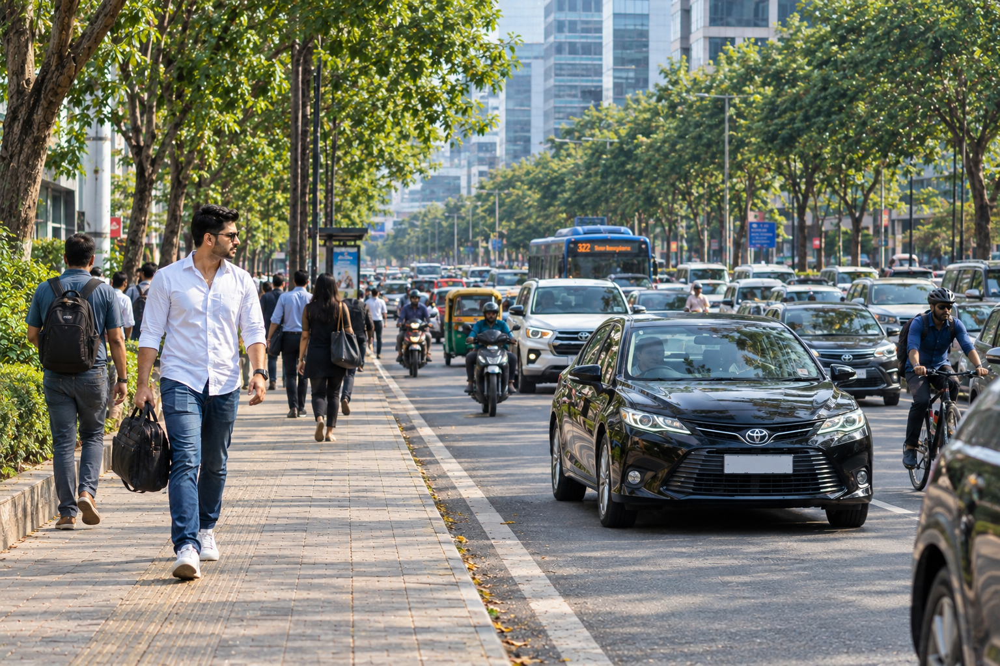

Image loaded: 01.png


In [3]:
# Open the Google Colab file picker.
uploaded = files.upload()

# Get the name of the first uploaded file.
IMAGE_PATH = next(iter(uploaded))

# Display the input image.
display(Image(filename=IMAGE_PATH))

print("Image loaded:", IMAGE_PATH)

## 🤖 5. Load the YOLO-World model

We will use **`yolov8s-worldv2.pt`**, a small YOLO-World model that is a practical choice for a Colab demonstration. The pretrained weights will download automatically the first time this cell runs.

In [4]:
# Load the pretrained YOLO-World model.
model = YOLOWorld("yolov8s-worldv2.pt")

print("YOLO-World model loaded successfully!")

YOLO-World model loaded successfully!


## 🎯 7. Create a function for prompt-based detection



In [26]:
# Set the confidence threshold used for all experiments.

# Create a reusable function for one prompt experiment.
def run_prompt_experiment(title, prompts, CONFIDENCE = 0.15):

    # Print the experiment name and the prompts being tested.
    print("\n" + "=" * 65)
    print(title)
    print("Text prompts:", ", ".join(prompts))
    print("=" * 65)

    # Tell YOLO-World which object categories to look for.
    model.set_classes(prompts)

    # Run detection on the uploaded image.
    results = model.predict(
        source=IMAGE_PATH,
        imgsz=960,
        conf=CONFIDENCE,
        iou=0.50,
        max_det=100,
        verbose=False
    )

    # Get the result for our single image.
    result = results[0]

    # Draw bounding boxes, labels and confidence scores on the image.
    annotated_image = result.plot()

    # Convert the image from OpenCV's BGR format to RGB for Matplotlib.
    annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

    # Display the annotated image.
    plt.figure(figsize=(16, 9))
    plt.imshow(annotated_image)
    plt.title(title, fontsize=16, weight="bold")
    plt.axis("off")
    plt.show()

    # Print the detected labels and confidence scores.
    if result.boxes is None or len(result.boxes) == 0:
        print("No objects detected for these prompts.")
    else:
        print("Detected objects:")

## 🧪 8. Run experiments


Experiment 1 - Only Black Car
Text prompts: black car


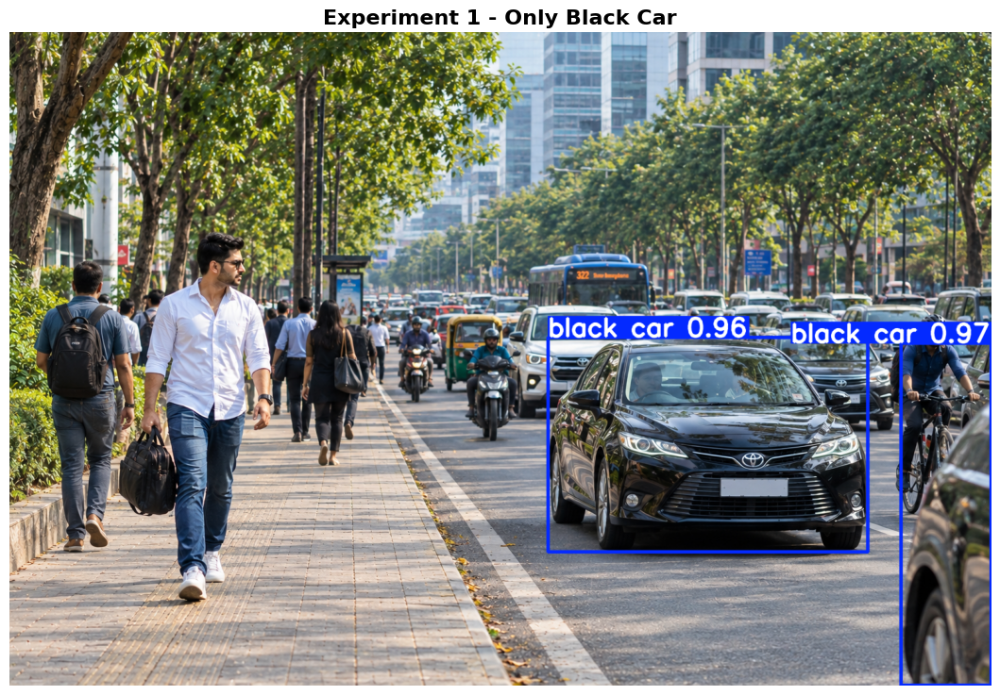

Detected objects:
- black car: 0.97
- black car: 0.96

Experiment 2 - Only Person with White shirt
Text prompts: person with white shirt


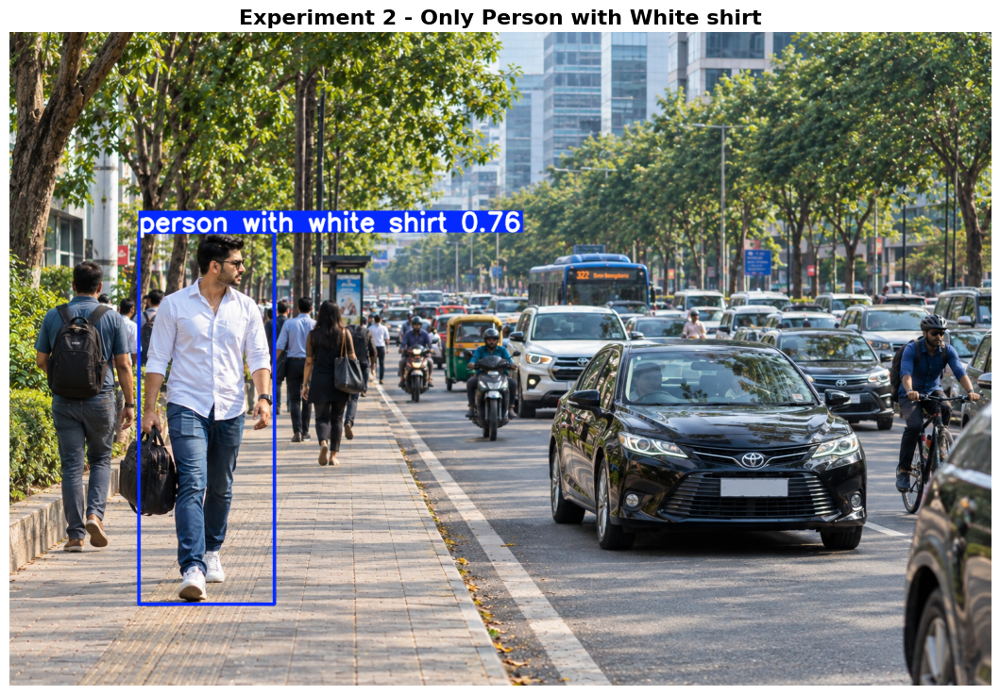

Detected objects:
- person with white shirt: 0.76

Experiment 3 - Only Person with Bag
Text prompts: person with bag


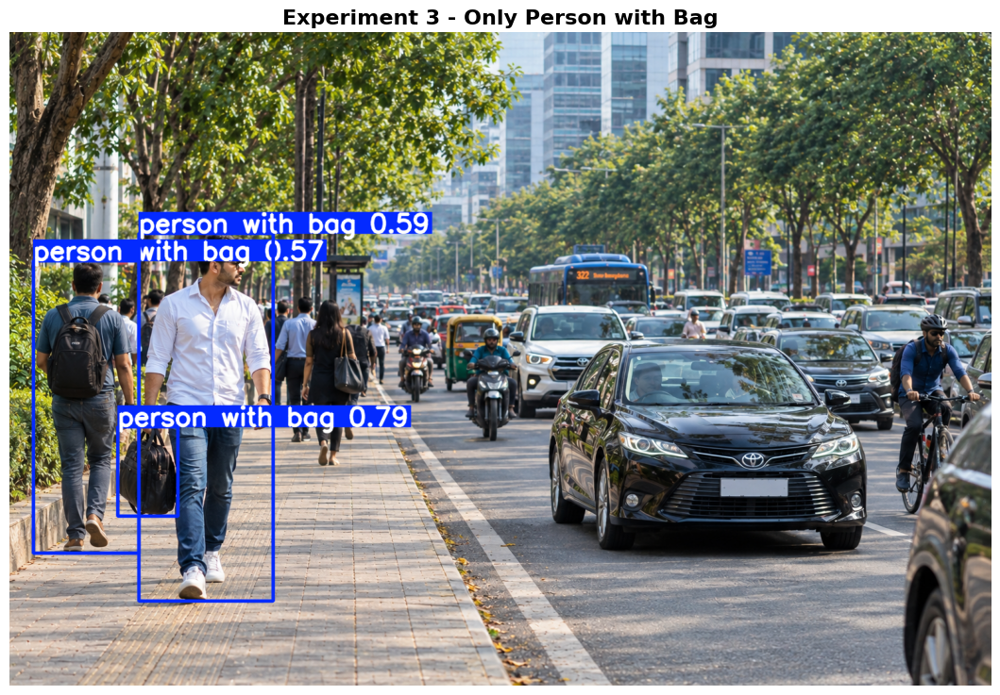

Detected objects:
- person with bag: 0.79
- person with bag: 0.59
- person with bag: 0.57

Experiment 4 - Only Bicycle
Text prompts: bicycle


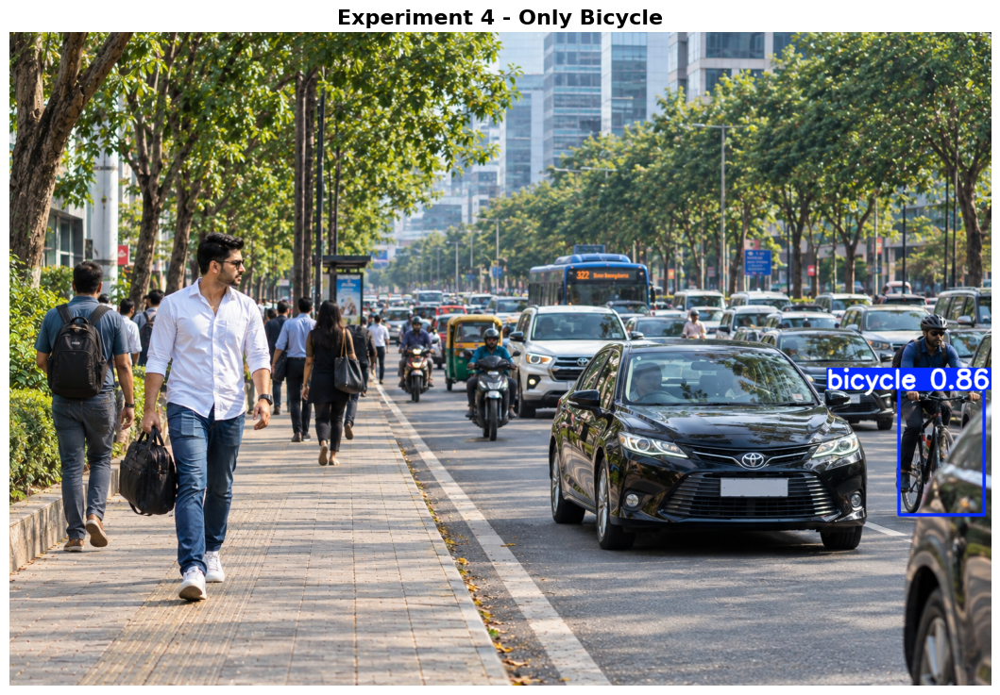

Detected objects:
- bicycle: 0.86

Experiment 5 - All objects
Text prompts: black car, person with white shirt, person with bag, bicycle


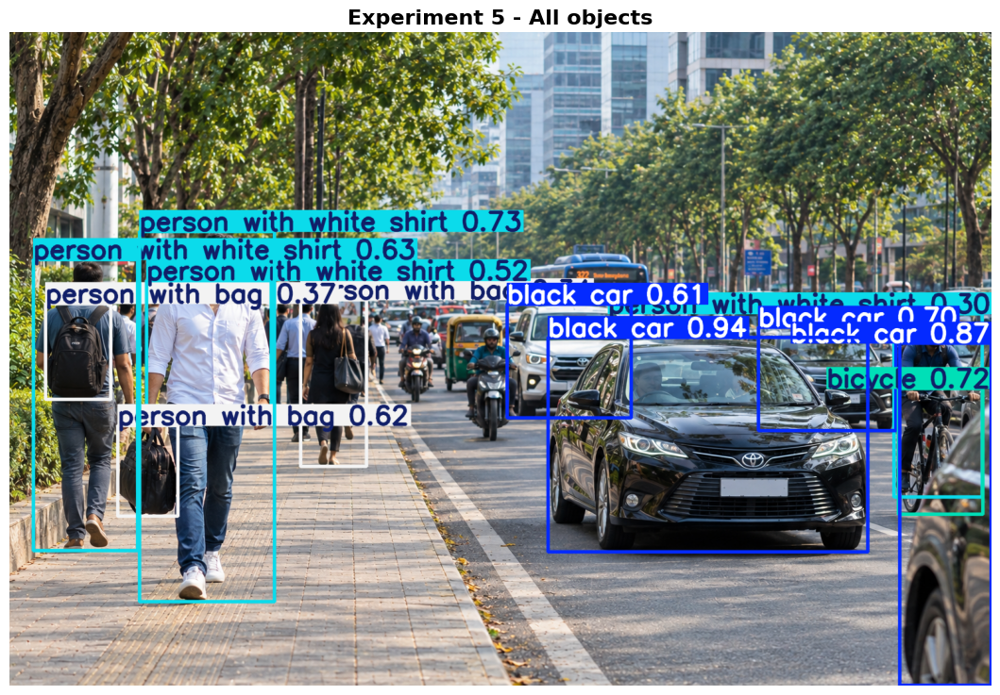

Detected objects:
- black car: 0.94
- black car: 0.87
- person with white shirt: 0.73
- bicycle: 0.72
- black car: 0.70
- person with white shirt: 0.63
- person with bag: 0.62
- black car: 0.61
- person with white shirt: 0.52
- person with bag: 0.37
- person with bag: 0.34
- person with white shirt: 0.30


In [25]:
# Experiment 1: Find pedestrians and personal items.

run_prompt_experiment(
    "Experiment 1 - Only Black Car",
    ["black car"],
    0.95
)
run_prompt_experiment(
    "Experiment 2 - Only Person with White shirt",
    ["person with white shirt"],
    0.5
)
run_prompt_experiment(
    "Experiment 3 - Only Person with Bag",
    ["person with bag"],
    0.5
)
run_prompt_experiment(
    "Experiment 4 - Only Bicycle",
    ["bicycle"],
    0.5
)
run_prompt_experiment(
    "Experiment 5 - All objects",
    ["black car",
     "person with white shirt",
     "person with bag",
     "bicycle"],
    0.3
)